


> ## YFINANCE



**INSTALACIÓN YFINANCE**

**IMPORTS**

In [23]:
# CODE

import pandas as pd
import matplotlib.pyplot as plt
import yfinance as yf
import datetime as dt

**OBJETO TICKER**

Genera un Ticker para los datos de Cocacola.

In [24]:
# CODE
ticker= yf.Ticker("KO")
               

**TICKER INFO**: Información genérica de la compañía.

In [25]:
# CODE
# CODE
ticker.history(period="max")
ticker.info
ticker.actions

,Dividends,Stock Splits
Date,,
1962-03-13 00:00:00-05:00,0.001563,0.0
1962-06-11 00:00:00-04:00,0.001563,0.0
1962-09-11 00:00:00-04:00,0.001563,0.0
1962-11-28 00:00:00-05:00,0.001563,0.0
1963-03-11 00:00:00-05:00,0.001758,0.0
...,...,...
2025-06-13 00:00:00-04:00,0.510000,0.0
2025-09-15 00:00:00-04:00,0.510000,0.0
2025-12-01 00:00:00-05:00,0.510000,0.0


Se aprecia que el dividendo por acción ha crecido de forma sostenida desde 1962 a **0,53** en el pago de junio de 2026, reflejando la política de "dividendo creciente" característica de Coca-Cola. 

**ACCIONES DE MERCADO**: Splits y dividendos.

In [26]:
# CODE
ticker.splits
ticker.dividends

Date
1962-03-13 09:30:00-05:00    0.001563
1962-06-11 09:30:00-04:00    0.001563
1962-09-11 09:30:00-04:00    0.001563
1962-11-28 09:30:00-05:00    0.001563
1963-03-11 09:30:00-05:00    0.001758
                               ...   
2025-06-13 09:30:00-04:00    0.510000
2025-09-15 09:30:00-04:00    0.510000
2025-12-01 09:30:00-05:00    0.510000
2026-03-13 09:30:00-04:00    0.530000
2026-06-15 09:30:00-04:00    0.530000
Name: Dividends, Length: 258, dtype: float64

Representa gráficamente los dividendos de Cocacola por año.

In [27]:
# CODE

# Preprocess
df = ticker.dividends
df = df.reset_index()
df


,Date,Dividends
0,1962-03-13 09:30:00-05:00,0.001563
1,1962-06-11 09:30:00-04:00,0.001563
2,1962-09-11 09:30:00-04:00,0.001563
3,1962-11-28 09:30:00-05:00,0.001563
4,1963-03-11 09:30:00-05:00,0.001758
...,...,...
253,2025-06-13 09:30:00-04:00,0.510000
254,2025-09-15 09:30:00-04:00,0.510000
255,2025-12-01 09:30:00-05:00,0.510000
256,2026-03-13 09:30:00-04:00,0.530000


In [28]:
df["Date"] = pd.to_datetime(df["Date"])

df["Año"] = df["Date"].dt.year

dividendos_anuales = df.groupby("Año")["Dividends"].sum()

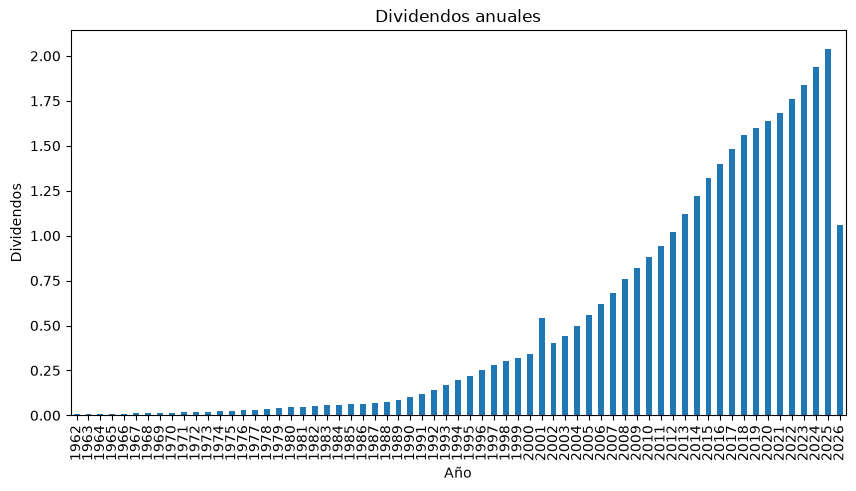

In [29]:
# Gráfico
dividendos_anuales.plot(kind="bar", figsize=(10,5))

plt.title("Dividendos anuales")
plt.xlabel("Año")
plt.ylabel("Dividendos")
plt.show()

La gráfica confirma el crecimiento del dividendo anual: apenas visibles hasta finales de los 80, empieza a acelerarse a partir de los 90 y crece de forma casi lineal desde 2000, alcanzando un máximo de 2,04 en 2025. La última barra (2026) cae a aproximadamente 1,06, pero no es una reduccion de dividendo si no son datos incompletos, ya que a fecha de la descarga (septiembre de 2026) solo se habían registrado 2 de los 4 pagos trimestrales del año. 

**ACCIONISTAS**: Accionistas principales y desglose de institucionales.

In [30]:
# CODE
ticker.major_holders

Breakdown,Value
insidersPercentHeld,0.09895
institutionsPercentHeld,0.68236
institutionsFloatPercentHeld,0.75729
institutionsCount,4653.00000


porcentaje de las acciones está en manos de: insiders, instituciones, y el número de instituciones que reportan posiciones. Un porcentaje alto de propiedad institucional suele indicar que el valor es seguido de cerca por fondos de inversión, lo que aporta liquidez pero también puede generar más volatilidad ante cambios de posición de grandes fondos.

In [31]:
ticker.institutional_holders

,Date Reported,Holder,pctHeld,Shares,Value,pctChange
0,2026-06-30,"Berkshire Hathaway, Inc",0.0930,400000000,35316000366,0.0000
1,2026-06-30,Blackrock Inc.,0.0750,322740471,28494756480,-0.0325
2,2026-06-30,Vanguard Capital Management LLC,0.0555,238798011,21083476609,0.0057
3,2026-06-30,State Street Corporation,0.0389,167399379,14779691325,0.0011
4,2026-06-30,"FMR, LLC",0.0254,109159806,9637719371,0.0147
5,2026-06-30,"Geode Capital Management, LLC",0.0246,105977991,9356796922,0.1401
6,2026-06-30,Vanguard Portfolio Management LLC,0.0232,99612603,8794796810,-0.0034
7,2026-06-30,Morgan Stanley,0.0209,89824129,7930572431,-0.0225
8,2026-06-30,"Charles Schwab Investment Management, Inc.",0.0188,80822520,7135820364,0.0587
9,2026-06-30,JPMORGAN CHASE & CO,0.0129,55484687,4898743066,-0.2140


El detalle institucional muestra que **Berkshire Hathaway** es, con diferencia, el mayor accionista individual (**9,3%**, 400 millones de acciones, 35.100 M$). Le siguen los grandes gestores pasivos **BlackRock (7,5%)**, **Vanguard (5,55% + 2,32% en dos vehículos distintos, ~7,9% combinado)** y **State Street (3,89%)**. 

**OPCIONES FINANCIERAS**: Información sobre opciones financieras.

Muestra todas las opciones abiertas de Cocacola, calls y puts.

In [32]:
# CODE
ticker.option_chain()

Options(calls=       contractSymbol             lastTradeDate  strike  lastPrice    bid  \
0   KO260918C00032500 2026-07-27 17:45:54+00:00    32.5      51.38  55.20   
1   KO260918C00035000 2026-09-04 19:06:00+00:00    35.0      53.00  52.05   
2   KO260918C00037500 2026-08-03 14:16:18+00:00    37.5      50.15  50.25   
3   KO260918C00040000 2026-07-21 19:23:04+00:00    40.0      42.55  49.95   
4   KO260918C00042500 2026-08-03 14:16:18+00:00    42.5      45.19  45.25   
5   KO260918C00045000 2026-09-11 18:13:23+00:00    45.0      43.44  42.00   
6   KO260918C00047500 2026-07-22 18:07:02+00:00    47.5      35.23  42.40   
7   KO260918C00050000 2026-07-22 18:07:19+00:00    50.0      32.60  39.95   
8   KO260918C00052500 2026-09-11 16:57:46+00:00    52.5      35.93  35.60   
9   KO260918C00055000 2026-07-31 19:30:21+00:00    55.0      32.59  32.70   
10  KO260918C00057500 2026-07-20 17:35:02+00:00    57.5      24.19  33.05   
11  KO260918C00060000 2026-08-13 18:18:11+00:00    60.0      2

mucho interés abierto en puts por debajo del precio actual sugiere cobertura frente a caídas, mientras que actividad elevada en calls por encima del precio indica apuestas alcistas.

**DESCARGA DE DATOS**

Descarga datos históricos de los tres objetos ticker para diferentes periodos e intervalos.

In [33]:
# CODE


Representa gráficamente los precios.

In [34]:
# CODE


Calcula un intervalo determinado hasta el día de hoy.

In [35]:
# CODE


**VARIOS ACTIVOS**

El objeto Ticker sólo permite descargar información sobre un activo. Para descargar varios hay que utilizar el objeto Tickers o la opción Download.

**TICKERS**

Descarga datos para Cocacola, Johnson & Johnson (JNJ), McDonald's

In [36]:
# CODE
datos = yf.download(
    tickers="KO JNJ MCD",period="max")

print(datos)

[*********************100%***********************]  3 of 3 completed

Price            Close                               High             \
Ticker             JNJ         KO         MCD         JNJ         KO   
Date                                                                   
1962-01-02    0.059702   0.044457         NaN    0.059702   0.045668   
1962-01-03    0.058774   0.043467         NaN    0.059083   0.043797   
1962-01-04    0.058155   0.043797         NaN    0.059083   0.044127   
1962-01-05    0.057227   0.042807         NaN    0.057691   0.044347   
1962-01-08    0.056299   0.042366         NaN    0.056763   0.042477   
...                ...        ...         ...         ...        ...   
2026-09-04  275.230011  88.070000  255.690002  277.799988  88.910004   
2026-09-08  269.119995  88.360001  255.809998  271.989990  88.550003   
2026-09-09  267.079987  87.550003  253.479996  270.100006  88.400002   
2026-09-10  266.350006  87.830002  253.050003  271.269989  88.959999   
2026-09-11  265.579987  88.290001  252.529999  270.399994  88.65

Se aprecia que **MCD tiene `NaN` en las fechas antiguas** (1962): McDonald's no cotizaba públicamente entonces (salió a bolsa en 1965), mientras que KO y JNJ sí tienen precio desde el inicio de la serie.

Obtén los precios de cotización.

In [37]:
# CODE
datos["Close"]

Ticker,JNJ,KO,MCD
Date,,,
1962-01-02,0.059702,0.044457,NaN
1962-01-03,0.058774,0.043467,NaN
1962-01-04,0.058155,0.043797,NaN
1962-01-05,0.057227,0.042807,NaN
1962-01-08,0.056299,0.042366,NaN
...,...,...,...
2026-09-04,275.230011,88.070000,255.690002
2026-09-08,269.119995,88.360001,255.809998
2026-09-09,267.079987,87.550003,253.479996


Los tres se mueven en rangos de precio muy distintos, por lo que es doficil comparar su evolución relativa por lo habría que normalizar las series en lugar de representarlas directamente.

Accede a la información de alguno de los tickers

In [38]:
# CODE
ticker = yf.Ticker("KO")
ticker.info

{'address1': 'One Coca-Cola Plaza',
 'city': 'Atlanta',
 'state': 'GA',
 'zip': '30313',
 'country': 'United States',
 'phone': '404 676 2121',
 'website': 'https://www.coca-colacompany.com',
 'industry': 'Beverages - Non-Alcoholic',
 'industryKey': 'beverages-non-alcoholic',
 'industryDisp': 'Beverages - Non - Alcoholic',
 'sector': 'Consumer Defensive',
 'sectorKey': 'consumer-defensive',
 'sectorDisp': 'Consumer Defensive',
 'longBusinessSummary': 'The Coca-Cola Company, a beverage company, manufactures and sells various nonalcoholic beverages in the United States and internationally. The company provides Trademark Coca-Cola, sparkling soft drinks and flavors; water, sports, coffee, and tea; juice, value-added dairy, and plant-based beverages; and emerging beverages. It also offers beverage concentrates and syrups, as well as fountain syrups to fountain retailers comprising restaurants and convenience stores. The company sells its products under the Coca-Cola, Diet Coke/Coca-Cola Li

**DOWNLOAD**

Descarga datos para varios tickers.

In [39]:
# CODE



Representa gráficamente los valores.

In [40]:
# CODE